# Protocol

## Libraries

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn import preprocessing
from sklearn.model_selection import TimeSeriesSplit

## Import and Tidy Data

In [69]:
df_train_y_Loc = pd.read_csv('data/Datasets_MLready_pred_Location/y_train_Loc.csv')
df_train_y_Loc.head()

,Location
0,Zch_Rosengartenstrasse
1,Zch_Schimmelstrasse
2,Zch_Stampfenbachstrasse
3,Zch_Rosengartenstrasse
4,Zch_Schimmelstrasse


In [70]:
df_train_X_Loc = pd.read_csv('data/Datasets_MLready_pred_Location/X_train_transformed_Loc.csv')
df_train_X_Loc.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,scaled__NO2,scaled__O3,scaled__PM10,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,-0.712877,-0.054805,0.408815,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,-1.165838,0.129167,0.175959,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,-0.966121,0.019975,1.296581,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,-0.315745,-0.138519,0.462871,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,-1.203824,0.154645,-0.327177,2018.0


In [71]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols_Loc = list(df_train_X_Loc.filter(like="Spline_").columns)
scaled_cols_Loc = list(df_train_X_Loc.filter(like="scaled_").columns)
encoded_cols_Loc = list(df_train_X_Loc.filter(like="encoded_").columns)
year_col_Loc = list(df_train_X_Loc.filter(like="remainder_").columns)
tri_cols_Loc = list(df_train_X_Loc.iloc[:,0:8].columns)

In [179]:
# plotting a pairplot
# df_pairplot = df.drop(columns=["Datetime", "Month", "Weekday", "YearMonth"])
#
# sns.set_theme(style="ticks")
#
# sns.pairplot(df_pairplot, hue="Location")

In [180]:
# df[["Month", "Weekday", "Year"]] = df[["Month", "Weekday", "Year"]].astype("category")
#
# df.dtypes

## 3. Time-based cross-validation

In [72]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

## 4. Model Evaluation

In [73]:
# model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    print("%.2f ± %.2f" % (rmse.mean(), rmse.std()))

In [74]:
X_tri_Loc = df_train_X_Loc[encoded_cols_Loc + tri_cols_Loc + scaled_cols_Loc + year_col_Loc]
X_spl_Loc = df_train_X_Loc[encoded_cols_Loc + spline_cols_Loc + scaled_cols_Loc + year_col_Loc]

In [80]:
y_Location = df_train_y_Loc["Location"]

# Map station names -> class codes (adjust names if needed)
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
y_train_Location_codes = y_Location.map(loc_to_code).astype("int64")

In [81]:
df_train_y_Loc.describe()
y_Location.describe()

count                      171398
unique                          3
top       Zch_Stampfenbachstrasse
freq                        59329
Name: Location, dtype: object

### Model 1 (e.g. Multiple Linear Regression)

In [186]:
# building linear regression model
model_lr = LinearRegression()

In [187]:
print("linear regression, trigonometric encoding, NO2")
evaluate(model_lr, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_lr, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_lr, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_lr, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_lr, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_lr, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
11.16 ± 3.46
linear regression, spline encoding, NO2
12.04 ± 3.90
linear regression, trigonometric encoding, O3
19.19 ± 3.26
linear regression, spline encoding, O3
35.44 ± 34.50
linear regression, trigonometric encoding, PM10
6.73 ± 1.43
linear regression, spline encoding, PM10
11.68 ± 10.90


### Model 2 - Lasso

In [188]:
# Build and evaluate a basic model
alpha = 0.1
model_lasso = Lasso(alpha=alpha)

print("linear regression, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
11.09 ± 3.55
linear regression, spline encoding, NO2
11.23 ± 3.41
linear regression, trigonometric encoding, O3
18.69 ± 3.38
linear regression, spline encoding, O3
18.29 ± 3.26
linear regression, trigonometric encoding, PM10
6.51 ± 0.73
linear regression, spline encoding, PM10
6.23 ± 0.33


### Model 3.1 - LDA 1D

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Build and evaluate a basic model
n_components = 1
model_LDA_1D = LDA(n_components=n_components)
X_train_lda = model_LDA_1D.fit_transform(X_tri, y_train_Location_codes)


print("LDA, trigonometric encoding, Location")
evaluate(model_LDA_1D, X_tri, y_train_Location_codes)

print("LDA, spline encoding, Location")
evaluate(model_LDA_1D, X_spl, y_train_Location_codes)

LDA, trigonometric encoding, Location
0.48 ± 0.05
LDA, spline encoding, Location
0.48 ± 0.06


### Model 3.2 - LDA 2D

In [44]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Map station names -> class codes (adjust names if needed)
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
y_train_Location_codes = y_Location.map(loc_to_code).astype("int64")



# Build and evaluate a basic model
n_components = 2
model_LDA_2D = LDA(n_components=n_components)
X_train_lda = model_LDA_1D.fit_transform(X_tri, y_train_Location_codes)


print("LDA, trigonometric encoding, Location")
evaluate(model_LDA_1D, X_tri, y_train_Location_codes)

print("LDA, spline encoding, Location")
evaluate(model_LDA_1D, X_spl, y_train_Location_codes)

LDA, trigonometric encoding, Location
0.48 ± 0.05
LDA, spline encoding, Location
0.48 ± 0.06


## 5. Feature selection

### Helper functions

In [50]:
# Build a grouping function
def group_features(feature_names):
    groups = {}
    for f in feature_names:
        # original variable name = prefix before first underscore
        base = f.split("__")[1].split("_")[0]
        groups.setdefault(base, []).append(f)
    return groups

# Compute grouped importance
def grouped_importance(model, X, y=None):
    # For Linear models
    if hasattr(model, "coef_"):
        raw = np.abs(model.coef_)
    # For Tree-based models
    elif hasattr(model, "feature_importances_"):
        raw = model.feature_importances_
    # Any other model without built-in importance
    else:
        if y is None:
            raise ValueError("y must be provided for models without built-in importance")
        # Sample from data, otherwise it is running very long
        X_sample = X.sample(5000, random_state=42)
        y_sample = y.loc[X_sample.index]
        permutation_result = permutation_importance(model, X_sample, y_sample, n_repeats=5, random_state=42)
        raw = permutation_result.importances_mean

    # Normalization
    normalized = raw / raw.sum()
    imp = pd.Series(normalized, index=X.columns)

    # Grouping
    groups = group_features(X.columns)
    grouped = {base: imp[cols].sum() for base, cols in groups.items()}

    return pd.Series(grouped).sort_values(ascending=False)

# Make grouped plots
def plot_grouped_importance_multi(
    plots,
    model_name,
    feature_order=None,
    figsize=(18, 6),
    sharey=True
):
    """
    Plot multiple grouped feature-importance comparisons (Trig vs Spline)
    in a single figure.

    Parameters
    ----------
    plots : list of dict
        Each dict must contain:
        {
            "tri_imp": pd.Series,
            "spl_imp": pd.Series,
            "feature_name": str
        }
    model_name : str
        Name of the model (used in titles).
    feature_order : list of str, optional
        Desired order of grouped features.
    figsize : tuple
        Figure size.
    sharey : bool
        Share y-axis across subplots.
    """

    if feature_order is None:
        feature_order = [
            "Year", "Month", "Weekday", "Time", "Day",
            #"Location",
            "NO2", "O3", "PM10",
            "Hr", "RainDur", "T", "WVv", "StrGlo",
            "meanVehicles"
        ]

    n = len(plots)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=sharey)

    # Make axes iterable even if n == 1
    if n == 1:
        axes = [axes]

    for ax, p in zip(axes, plots):

        # Build grouped importance table
        df = pd.DataFrame({
            "Trig importance": p["tri_imp"],
            "Spline importance": p["spl_imp"]
        }).fillna(0)

        # Reorder and clean
        df = df.reindex(feature_order)
        df = df.dropna(how="all")

        if df.empty:
            ax.set_title(f'{p["feature_name"]} (no features)')
            ax.axis("off")
            continue

        df.plot(kind="bar", width=0.8, ax=ax)

        # Annotate bars
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

        ax.set_title(f'{model_name} – {p["feature_name"]}')
        ax.set_xlabel("Original Variable")
        ax.tick_params(axis="x", rotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha("right")

    axes[0].set_ylabel("Normalized Importance")
    fig.suptitle(f"{model_name} Feature Importance (Grouped)", y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()

### Model 2 - Lasso

#### Feature importance analysis

In [190]:
# Train the models for the individual datasets
alpha = 0.1

lasso_tri_NO2 = Lasso(alpha=alpha).fit(X_tri, y_NO2)
lasso_spl_NO2 = Lasso(alpha=alpha).fit(X_spl, y_NO2)

lasso_tri_O3 = Lasso(alpha=alpha).fit(X_tri, y_O3)
lasso_spl_O3 = Lasso(alpha=alpha).fit(X_spl, y_O3)

lasso_tri_PM10 = Lasso(alpha=alpha).fit(X_tri, y_PM10)
lasso_spl_PM10 = Lasso(alpha=alpha).fit(X_spl, y_PM10)

# Compute importance for all 6 models
imp_lasso_tri_NO2 = get_importance(lasso_tri_NO2, X_tri.columns)
imp_lasso_spl_NO2 = get_importance(lasso_spl_NO2, X_spl.columns)

imp_lasso_tri_O3 = get_importance(lasso_tri_O3, X_tri.columns)
imp_lasso_spl_O3 = get_importance(lasso_spl_O3, X_spl.columns)

imp_lasso_tri_PM10 = get_importance(lasso_tri_PM10, X_tri.columns)
imp_lasso_spl_PM10 = get_importance(lasso_spl_PM10, X_spl.columns)

# Build grouped importance tables for all 6 models
g_imp_lasso_tri_NO2 = grouped_importance(lasso_tri_NO2, X_tri)
g_imp_lasso_spl_NO2 = grouped_importance(lasso_spl_NO2, X_spl)

g_imp_lasso_tri_O3 = grouped_importance(lasso_tri_O3, X_tri)
g_imp_lasso_spl_O3 = grouped_importance(lasso_spl_O3, X_spl)

g_imp_lasso_tri_PM10 = grouped_importance(lasso_tri_PM10, X_tri)
g_imp_lasso_spl_PM10 = grouped_importance(lasso_spl_PM10, X_spl)

<Figure size 1000x600 with 0 Axes>

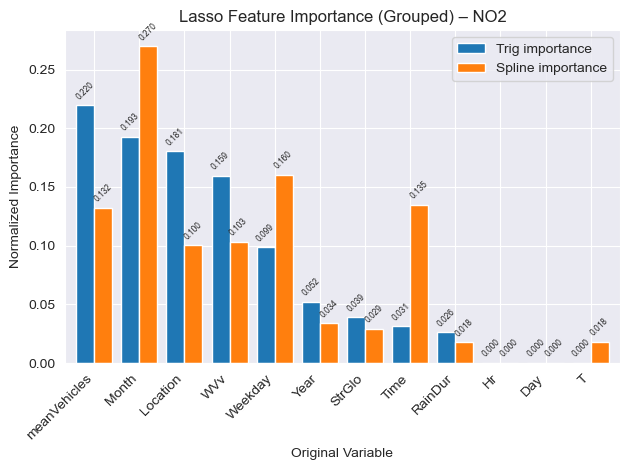

<Figure size 1000x600 with 0 Axes>

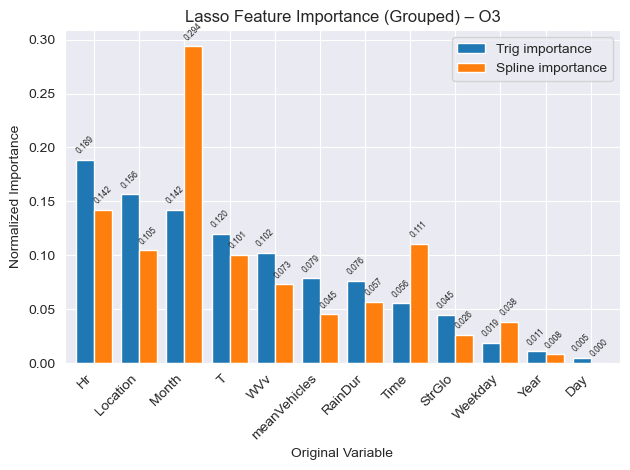

<Figure size 1000x600 with 0 Axes>

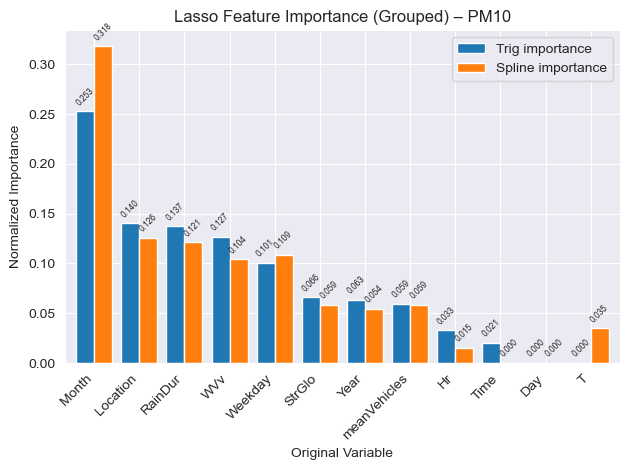

In [191]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lasso_tri_NO2, g_imp_lasso_spl_NO2, "NO2")
plot_grouped_importance(g_imp_lasso_tri_O3,  g_imp_lasso_spl_O3,  "O3")
plot_grouped_importance(g_imp_lasso_tri_PM10, g_imp_lasso_spl_PM10, "PM10")


No feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

### Model 3.1 - LDA 1D

### Helper functions

In [52]:
def get_importance_lda_loadings(model, feature_names, agg="varweighted", k=None):
    """
    Importance from LDA discriminant loadings (solver='svd'):
      'absmean'     : mean |loading| across axes
      'absmax'      : max |loading| across axes
      'varweighted' : |loading| weighted by explained_variance_ratio_
    k: number of axes to aggregate (default: all)
    """
    if not hasattr(model, "scalings_"):
        raise ValueError("Use solver='svd' to get scalings_.")

    load = np.asarray(model.scalings_)  # (n_features, n_components)
    n_comp = load.shape[1]
    if k is None:
        k = n_comp
    L = np.abs(load[:, :k])

    if agg == "absmax":
        imp = L.max(axis=1)
    elif agg == "absmean":
        imp = L.mean(axis=1)
    else:  # varweighted
        w = getattr(model, "explained_variance_ratio_", None)
        if w is None:
            imp = L.mean(axis=1)
        else:
            w = np.asarray(w)[:k]
            w = w / (w.sum() + 1e-12)
            imp = (L * w).sum(axis=1)

    imp = imp / (imp.sum() + 1e-12)
    return pd.Series(imp, index = list(model.feature_names_in_)).sort_values(ascending=False)


def grouped_from_series(importance_series, X):
    groups = group_features(X.columns)
    grouped = {base: importance_series[cols].sum() for base, cols in groups.items()}
    return pd.Series(grouped).sort_values(ascending=False)



import numpy as np
import pandas as pd

def get_importance_lda(model, feature_names, agg="l2"):
    """
    Per-feature importance from LDA coef_.
    Works for binary and multiclass by aggregating across class rows.

    Parameters
    ----------
    model : fitted sklearn.discriminant_analysis.LinearDiscriminantAnalysis
        Must expose coef_.
    feature_names : list-like
        Names in the same order used to fit the model.
    agg : {'l2','l1','max'}
        How to aggregate across classes when multiclass:
          - 'l2'  : Euclidean norm across classes (default, robust)
          - 'l1'  : Sum of absolute coefs across classes
          - 'max' : Max absolute coef across classes

    Returns
    -------
    pandas.Series
        Normalized importance per feature (sums to 1), sorted descending.
    """
    coef = np.asarray(model.coef_)
    if coef.ndim == 2 and coef.shape[0] > 1:
        if agg == "l1":
            imp = np.abs(coef).sum(axis=0)
        elif agg == "max":
            imp = np.abs(coef).max(axis=0)
        else:  # 'l2'
            imp = np.sqrt((coef ** 2).sum(axis=0))
    else:
        imp = np.abs(coef).ravel()

    imp = imp / (imp.sum() + 1e-12)

    if len(feature_names) != imp.shape[0]:
        raise ValueError(
            f"Feature length mismatch: {len(feature_names)} names vs {imp.shape[0]} coefficients."
        )

    return pd.Series(imp, index=feature_names).sort_values(ascending=False)


# Example builds
#g_imp_lda_coef  = grouped_from_series(imp_lda, X)        # from coef_
#g_imp_lda_load  = grouped_from_series(imp_lda_load, X)   # from loadings
#g_imp_lda_perm  = grouped_from_series(imp_perm, X)       # from permutation


#### Feature importance analysis

In [58]:
n_components = 1
solver = "svd"

model_lda_tri = LDA(n_components=n_components, solver=solver).fit(X_tri, y_Location)
model_lda_spl = LDA(n_components=n_components, solver=solver).fit(X_spl, y_Location)

# Compute importance on the matching columns
imp_lda_coef_tri  = get_importance_lda(model_lda_tri,  X_tri.columns,  agg="l2")
imp_lda_coef_spl  = get_importance_lda(model_lda_spl,  X_spl.columns,  agg="l2")
imp_lda_load_tri  = get_importance_lda_loadings(model_lda_tri,  X_tri.columns,  agg="varweighted")
imp_lda_load_spl  = get_importance_lda_loadings(model_lda_spl,  X_spl.columns,  agg="varweighted")

# Group with matching X
g_imp_lda_coef_tri = grouped_from_series(imp_lda_coef_tri, X_tri)
g_imp_lda_load_tri = grouped_from_series(imp_lda_load_tri, X_tri)

g_imp_lda_coef_spl = grouped_from_series(imp_lda_coef_spl, X_spl)
g_imp_lda_load_spl = grouped_from_series(imp_lda_load_spl, X_spl)


<Figure size 1000x600 with 0 Axes>

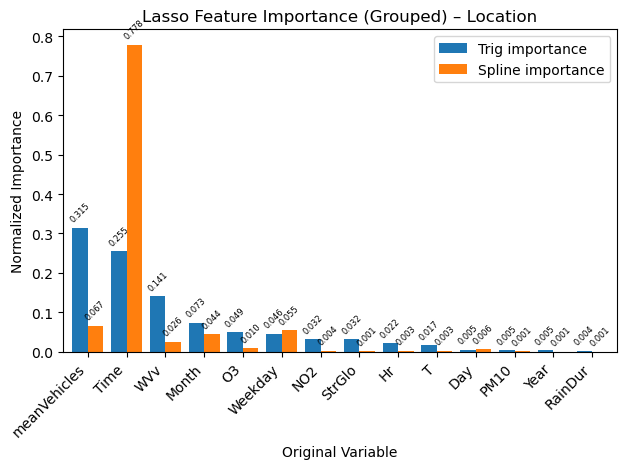

In [59]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lda_coef_tri, g_imp_lda_coef_spl, "Location")

### Model 3.2 - LDA 2D

#### Feature importance analysis

In [56]:
n_components = 2
solver = "svd"

model_lda_tri = LDA(n_components=n_components, solver=solver).fit(X_tri, y_Location)
model_lda_spl = LDA(n_components=n_components, solver=solver).fit(X_spl, y_Location)

# Compute importance on the matching columns
imp_lda_coef_tri  = get_importance_lda(model_lda_tri,  X_tri.columns,  agg="l2")
imp_lda_coef_spl  = get_importance_lda(model_lda_spl,  X_spl.columns,  agg="l2")
imp_lda_load_tri  = get_importance_lda_loadings(model_lda_tri,  X_tri.columns,  agg="varweighted")
imp_lda_load_spl  = get_importance_lda_loadings(model_lda_spl,  X_spl.columns,  agg="varweighted")

# Group with matching X
g_imp_lda_coef_tri = grouped_from_series(imp_lda_coef_tri, X_tri)
g_imp_lda_load_tri = grouped_from_series(imp_lda_load_tri, X_tri)

g_imp_lda_coef_spl = grouped_from_series(imp_lda_coef_spl, X_spl)
g_imp_lda_load_spl = grouped_from_series(imp_lda_load_spl, X_spl)

<Figure size 1000x600 with 0 Axes>

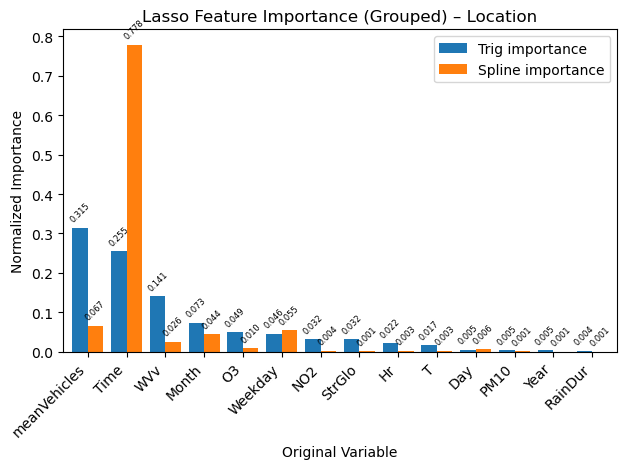

In [60]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lda_coef_tri, g_imp_lda_coef_spl, "Location")

## 5. Hyperparameter Tuning

### Model 1

### Model 2

### Model 3

In [62]:
# Find all hyperparams of the model
n_components = 1
model_LDA_2D = LDA(n_components=n_components)
model_LDA_2D.get_params()

{'covariance_estimator': None,
 'n_components': 1,
 'priors': None,
 'shrinkage': None,
 'solver': 'svd',
 'store_covariance': False,
 'tol': 0.0001}

In [63]:
# Find all hyperparams of the model
n_components = 2
model_LDA_2D = LDA(n_components=n_components)
model_LDA_2D.get_params()

{'covariance_estimator': None,
 'n_components': 2,
 'priors': None,
 'shrinkage': None,
 'solver': 'svd',
 'store_covariance': False,
 'tol': 0.0001}

## 6. Model Evaluation Metrics

averaged across CV splits during model selection
reported on the final test year (2025)
- RMSE
- MAE

## 7. Model Selection

Compare all models (e.g. linear regression, random forest, ...)

- Mean CV RMSE
- Stability across folds (standard deviation)
- Interpretability
- Computational complexity

## 8. Final Training and Testing

With the best model only, not all of them

- The selected model is refit on all training data (2018–2024)
- Predictions are generated for 2025
- Final performance is reported on the test set

### Model 1 (Multiple Linear Regression)

In [192]:
# fitting the model
model_lr.fit(X_tri, y_NO2)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [193]:
df_test_X = pd.read_csv("data/Datasets_MLready/X_test_transformed.csv")
df_test_y = pd.read_csv("data/Datasets_MLready/y_test.csv")

In [194]:
y_NO2_test = df_test_y["NO2"]
y_NO2_test.describe()

count    25853.000000
mean        23.773432
std         13.584978
min          0.690000
25%         13.380000
50%         21.790000
75%         31.970000
max         95.510000
Name: NO2, dtype: float64

In [195]:
X_tri_test = df_test_X[encoded_cols + tri_cols + scaled_cols]
X_spl_test = df_test_X[spline_cols + tri_cols + scaled_cols]

In [196]:
predictions = model_lr.predict(X_tri_test)

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- remainder__Year


In [19]:
# model evaluation
print('mean_squared_error:', mean_squared_error(y_NO2_test, predictions))
print('mean_absolute_error:', mean_absolute_error(y_NO2_test, predictions))

mean_squared_error: 144.96042374933515
mean_absolute_error: 9.889888824026027


### Model 2 (Multiple Linear Regression)

In [84]:
df_test_X = pd.read_csv("data/Datasets_MLready_pred_Location/X_test_transformed_Loc.csv")
df_test_y = pd.read_csv("data/Datasets_MLready_pred_Location/y_test_Loc.csv")


=== Fold 1 ===
Test size: 720 | Accuracy: 0.824 | Balanced Accuracy: 0.823
                     precision    recall  f1-score   support

 Rosengartenstrasse       0.93      0.75      0.83       239
    Schimmelstrasse       0.68      0.91      0.78       242
Stampfenbachstrasse       0.96      0.81      0.88       239

           accuracy                           0.82       720
          macro avg       0.85      0.82      0.83       720
       weighted avg       0.85      0.82      0.83       720


=== Fold 2 ===
Test size: 720 | Accuracy: 0.800 | Balanced Accuracy: 0.801
                     precision    recall  f1-score   support

 Rosengartenstrasse       0.92      0.65      0.76       241
    Schimmelstrasse       0.65      0.94      0.77       238
Stampfenbachstrasse       0.94      0.81      0.87       241

           accuracy                           0.80       720
          macro avg       0.84      0.80      0.80       720
       weighted avg       0.84      0.80      0.80

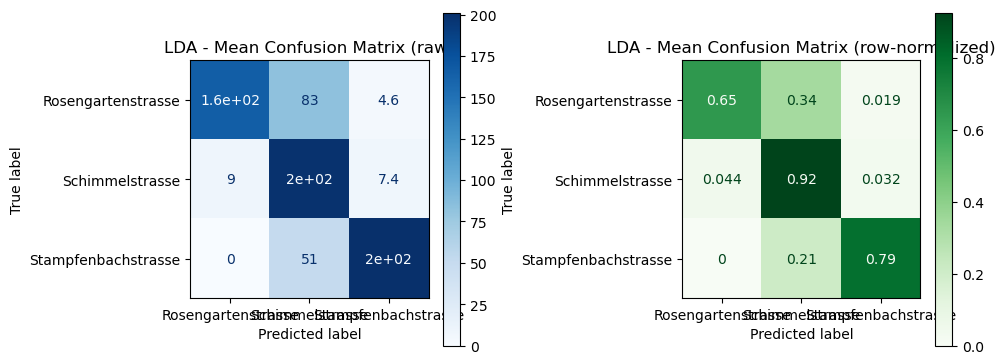

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, balanced_accuracy_score, classification_report
)
"""
# -----------------------------
# 1) Prepare labels & constants
# -----------------------------
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
display_labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']

# Ensure 1-D label Series, time-ordered X_all and y_all
y_codes = pd.Series(y_Location).map(loc_to_code).astype("int64")

# Feature columns: use all transformed columns (or a curated subset if you prefer)
feature_columns = df_train_X.columns.tolist()

# Your time series CV splitter
tss = TimeSeriesSplit(n_splits=5, gap=24*2, max_train_size=24 * 365, test_size=24 * 30)
"""
# ------------------------------------------
# 2) Run CV folds: fit imputer + LDA per fold
# ------------------------------------------
fold_metrics = []
cms = []         # raw confusion matrices per fold
cms_norm = []    # normalized confusion matrices (row-normalized) per fold

for fold_idx, (train_idx, test_idx) in enumerate(tss.split(df_train_X, y_codes), start=1):
    X_tr = df_train_X.iloc[train_idx][feature_columns]
    X_te = df_train_X.iloc[test_idx][feature_columns]
    y_tr = y_codes.iloc[train_idx].values
    y_te = y_codes.iloc[test_idx].values

    # Fit imputer on TRAIN only; transform train & test
    #imp = SimpleImputer(strategy="median")
    #X_tr_imp = imp.fit_transform(X_tr)
    #X_te_imp = imp.transform(X_te)

    # LDA (up to K-1 components; with 3 classes, 2 components available)
    n_classes = np.unique(y_codes).size
    n_components = min(n_classes - 1, 2)
    lda = LDA(n_components=n_components, solver="svd")
    lda.fit(X_tr, y_tr)

    # Predict on TEST
    y_pred = lda.predict(X_te)

    # Confusion matrices
    cm = confusion_matrix(y_te, y_pred, labels=[0, 1, 2])
    cm_n = confusion_matrix(y_te, y_pred, labels=[0, 1, 2], normalize='true')

    cms.append(cm)
    cms_norm.append(cm_n)

    # Metrics
    acc = accuracy_score(y_te, y_pred)
    bacc = balanced_accuracy_score(y_te, y_pred)

    fold_metrics.append({
        "fold": fold_idx,
        "accuracy": acc,
        "balanced_accuracy": bacc,
        "n_test": len(test_idx)
    })

    # Optional: per-fold report (comment out if too verbose)
    print(f"\n=== Fold {fold_idx} ===")
    print(f"Test size: {len(test_idx)} | Accuracy: {acc:.3f} | Balanced Accuracy: {bacc:.3f}")
    print(classification_report(y_te, y_pred, target_names=display_labels))

# ---------------------------------
# 3) Aggregate metrics & matrices
# ---------------------------------
metrics_df = pd.DataFrame(fold_metrics)
print("\nCV metrics (per fold):")
print(metrics_df.round(3))

print("\nMean ± Std across folds:")
print(pd.DataFrame({
    "accuracy_mean":   [metrics_df["accuracy"].mean()],
    "accuracy_std":    [metrics_df["accuracy"].std(ddof=1)],
    "balanced_mean":   [metrics_df["balanced_accuracy"].mean()],
    "balanced_std":    [metrics_df["balanced_accuracy"].std(ddof=1)],
}).round(3))

# Aggregate confusion matrices by simple average (element-wise)
cm_mean     = np.mean(np.stack(cms, axis=0), axis=0)
cm_norm_mean = np.mean(np.stack(cms_norm, axis=0), axis=0)

# -------------------------------
# 4) Plot averaged confusion matrix
# -------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_mean, display_labels=display_labels)
disp.plot(cmap="Blues", ax=ax[0], colorbar=True)
ax[0].set_title("LDA - Mean Confusion Matrix (raw)")

disp_n = ConfusionMatrixDisplay(confusion_matrix=cm_norm_mean, display_labels=display_labels)
disp_n.plot(cmap="Greens", ax=ax[1], colorbar=True)
ax[1].set_title("LDA - Mean Confusion Matrix (row-normalized)")

plt.tight_layout()
plt.show()
